## **Learning Strategy Implementation Assignment**
Melinda Annastasia Budijono - 24/54280/PA/23052

**Deskripsi Proyek**

Notebook ini merupakan mereplikasi contoh implementasi *fully connected layer* untuk pengenalan digit tulisan tangan (MNIST) serta berbagai metode untuk menangani *overfitting*.


### 1.  Import Library & Load Data

Dataset MNIST *Handwritten Digit* dibagi menjadi:
- 55.000 data training
- 10.000 data test
- 5.000 data validasi

Setiap gambar berukuran 28 x 28 piksel, dan label kelas diubah menjadi *one-hot encoded*.

In [1]:
import keras
from keras.datasets import mnist
from keras.models import Sequential, load_model
from keras.layers import Flatten, Dense
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report


In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

X_train /= 255
X_test /= 255

y_train = keras.utils.to_categorical(y_train, 10)
y_test = keras.utils.to_categorical(y_test, 10)

print('X_train shape:', X_train.shape)
print('X_test shape :', X_test.shape)
print('y_train shape:', y_train.shape)
print('y_test shape :', y_test.shape)

X_train shape: (60000, 28, 28, 1)
X_test shape : (10000, 28, 28, 1)
y_train shape: (60000, 10)
y_test shape : (10000, 10)


### 2. Define Model

Arsitektur ANN yang digunakan untuk pengenalan digit:
- Input layer berukuran 784 (hasil flatten dari 28x28)
- 1 hidden layer (dense) dengan 64 neuron, aktivasi ReLU
- Output layer dengan 10 neuron (10 label kelas), aktivasi Softmax

In [3]:
model1 = Sequential()
model1.add(Flatten())
model1.add(Dense(64, activation='relu'))
model1.add(Dense(10, activation='softmax'))

### 3. Compile Model, Fit Model, Save Model, dan Evaluate Model

In [4]:
model1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['acc'])

history1 = model1.fit(
    X_train, y_train,
    epochs=10,
    batch_size=100,
    validation_data=(X_test, y_test)
)

model1.summary()

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - acc: 0.8912 - loss: 0.3991 - val_acc: 0.9366 - val_loss: 0.2213
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - acc: 0.9449 - loss: 0.1929 - val_acc: 0.9508 - val_loss: 0.1647
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - acc: 0.9580 - loss: 0.1444 - val_acc: 0.9577 - val_loss: 0.1363
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - acc: 0.9665 - loss: 0.1162 - val_acc: 0.9611 - val_loss: 0.1210
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - acc: 0.9722 - loss: 0.0969 - val_acc: 0.9641 - val_loss: 0.1110
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - acc: 0.9762 - loss: 0.0826 - val_acc: 0.9680 - val_loss: 0.1039
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - acc: 0.9795 - loss: 0.0713 - val_acc: 0.9691 - val_loss: 0.0981
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - acc: 0.9821 - loss: 0.0622 - val_acc: 0.9705 - val_loss: 0.0939
Epoch 9/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - ac

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (100, 784)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (100, 64)              │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (100, 10)              │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 152,672 (596.38 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 101,782 (397.59 KB)

In [5]:
model1.save('my_model1.h5')

loss, accuracy = model1.evaluate(X_test, y_test)
print('Test loss    :', loss)
print('Test accuracy:', accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - acc: 0.9720 - loss: 0.0888
Test loss    : 0.08879081159830093
Test accuracy: 0.972000002861023


### 4. Visualisasi Evaluasi Model

Plot training loss vs validation loss selama proses training.

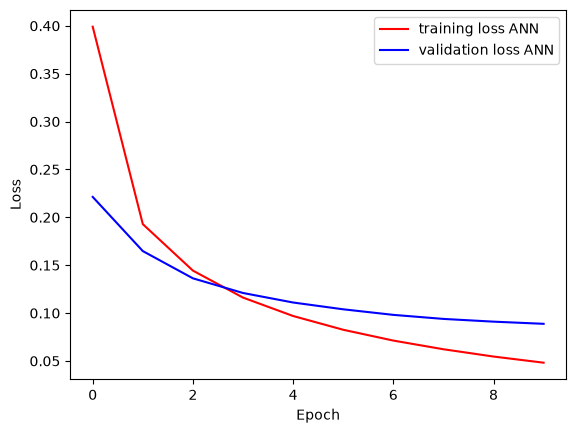

In [6]:
epochs = range(len(history1.history['loss']))
loss1 = history1.history['loss']
val_loss1 = history1.history['val_loss']

plt.plot(epochs, loss1, 'r', label='training loss ANN')
plt.plot(epochs, val_loss1, 'b', label='validation loss ANN')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

### 5. Load Model dan Prediksi

Memuat kembali model yang telah disimpan, lalu melakukan prediksi pada data test dan membandingkan label aktual vs label hasil prediksi.

In [7]:
model_simpan = load_model('my_model1.h5')
pred = model_simpan.predict(X_test)

idx = 30
print('label actual    :', np.argmax(y_test[idx]))
print('label prediction:', np.argmax(pred[idx]))

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
label actual    : 3
label prediction: 3


### 6. Overfit Handling

Menggunakan metode yang telah disampaikan pada tugas untuk menangani *overfitting* yang terjadi. Seed dibuat konsisten 42. Loop untuk mencari rate terbaik masing-masing metode, hasil val_loss terendah akan menjadi rate pilihan. tampilkan the model.summary(), performance and loss chart. buatkan juga val_loss graphic bandingin semua rate-nya.

#### 6.0 Setup & Fungsi Bantu

Semua percobaan memakai seed 42, arsitektur yang sama (Flatten → Dense 64 ReLU → Dense 10 Softmax), `batch_size=100`, dan data validasi yang sama dengan bagian 3 (`X_test`).

**Catatan pemilihan rate:** pada L1/L2, nilai `val_loss` dari Keras ikut menambahkan penalti regularisasi, sehingga rate kecil selalu terlihat "lebih baik" hanya karena penaltinya kecil. Agar adil, rate terbaik dipilih dari **val_loss cross-entropy murni** (metrik `ce`, tanpa penalti) pada model akhir. Untuk model tanpa L1/L2, nilainya sama persis dengan `val_loss`.

Baseline               | tanpa regularisasi     | epochs=20 | val_loss=0.0974 | val_acc=0.9739

>> Rate terbaik Baseline: tanpa regularisasi


,rate,epochs,val_loss,val_acc
0,tanpa regularisasi,20,0.0974,0.9739


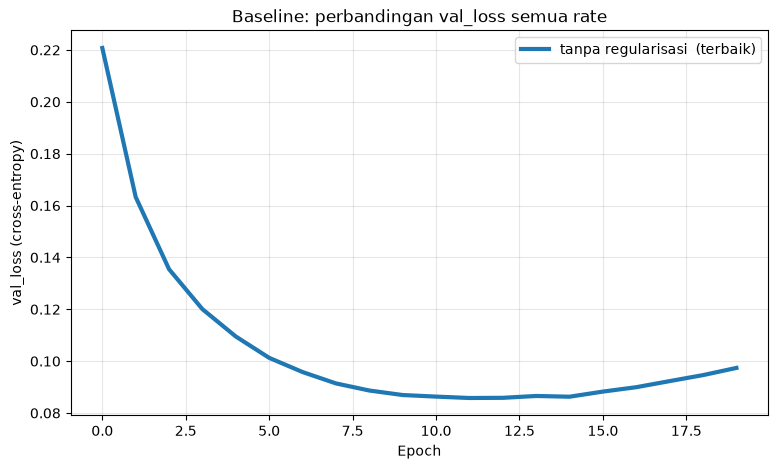

Model terbaik Baseline -> tanpa regularisasi


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 152,672 (596.38 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 101,782 (397.59 KB)

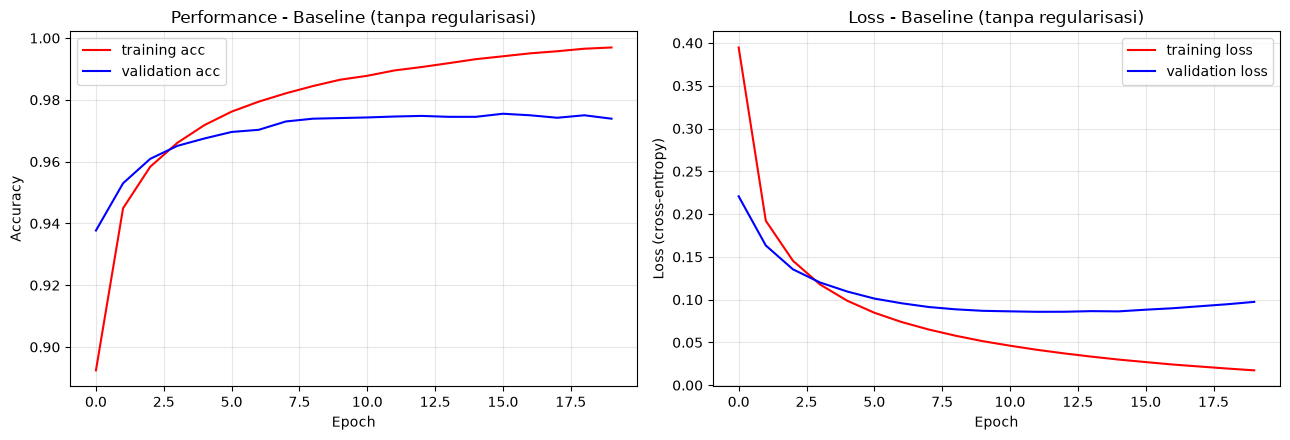

              precision    recall  f1-score   support

           0     0.9769    0.9908    0.9838       980
           1     0.9911    0.9850    0.9881      1135
           2     0.9628    0.9777    0.9702      1032
           3     0.9563    0.9743    0.9652      1010
           4     0.9716    0.9756    0.9736       982
           5     0.9804    0.9529    0.9665       892
           6     0.9852    0.9760    0.9806       958
           7     0.9841    0.9621    0.9729      1028
           8     0.9720    0.9610    0.9664       974
           9     0.9593    0.9802    0.9696      1009

    accuracy                         0.9739     10000
   macro avg     0.9740    0.9736    0.9737     10000
weighted avg     0.9740    0.9739    0.9739     10000



In [9]:
from keras import regularizers
from keras.layers import Dropout
from keras.callbacks import EarlyStopping

SEED = 42
EPOCHS = 20      # lebih panjang dari bagian 3 agar overfitting terlihat
BATCH = 100

best_per_method = []   # ringkasan rate terbaik tiap metode, dipakai di Kesimpulan


def build_model(l1=0.0, l2=0.0, dropout=0.0):
    """Model ANN yang sama dengan bagian 2, ditambah regularisasi/dropout opsional."""
    keras.utils.set_random_seed(SEED)
    if l1 and l2:
        reg = regularizers.l1_l2(l1=l1, l2=l2)
    elif l1:
        reg = regularizers.l1(l1)
    elif l2:
        reg = regularizers.l2(l2)
    else:
        reg = None

    model = Sequential()
    model.add(keras.Input(shape=(28, 28, 1)))
    model.add(Flatten())
    model.add(Dense(64, activation='relu', kernel_regularizer=reg))
    if dropout > 0:
        model.add(Dropout(dropout, seed=SEED))
    model.add(Dense(10, activation='softmax'))

    model.compile(optimizer='adam', loss='categorical_crossentropy',
                  metrics=['acc', keras.metrics.CategoricalCrossentropy(name='ce')])
    return model


def run_search(method, configs, epochs=EPOCHS):
    """configs: list of (label, kwargs_build_model, fungsi_pembuat_callbacks atau None)."""
    results = {}
    for label, model_kw, make_callbacks in configs:
        model = build_model(**model_kw)
        callbacks = make_callbacks() if make_callbacks else []
        hist = model.fit(X_train, y_train, epochs=epochs, batch_size=BATCH,
                         validation_data=(X_test, y_test), callbacks=callbacks, verbose=0)
        ev = model.evaluate(X_test, y_test, verbose=0, return_dict=True)
        results[label] = {'model': model, 'history': hist.history,
                          'val_loss': ev['ce'], 'val_acc': ev['acc'],
                          'epochs': len(hist.history['loss'])}
        print(f"{method:<22} | {label:<22} | epochs={results[label]['epochs']:>2} "
              f"| val_loss={ev['ce']:.4f} | val_acc={ev['acc']:.4f}")

    best = min(results, key=lambda k: results[k]['val_loss'])
    print(f"\n>> Rate terbaik {method}: {best}")
    return results, best


def show_results(method, results, best):
    # 1) Tabel semua rate
    df = pd.DataFrame([{'rate': k, 'epochs': v['epochs'],
                        'val_loss': round(v['val_loss'], 4),
                        'val_acc': round(v['val_acc'], 4)} for k, v in results.items()])
    display(df.sort_values('val_loss').reset_index(drop=True))

    # 2) Grafik perbandingan val_loss semua rate
    plt.figure(figsize=(9, 5))
    for label, r in results.items():
        lw = 3 if label == best else 1.3
        plt.plot(r['history']['val_ce'], linewidth=lw,
                 label=f"{label}{'  (terbaik)' if label == best else ''}")
    if method != 'Baseline':
        bh = baseline_results[baseline_best]['history']
        plt.plot(bh['val_ce'], 'k--', linewidth=1.8, label='baseline')
    plt.title(f'{method}: perbandingan val_loss semua rate')
    plt.xlabel('Epoch'); plt.ylabel('val_loss (cross-entropy)')
    plt.legend(); plt.grid(alpha=.3); plt.show()

    # 3) Model terbaik: summary, performance & loss chart
    r = results[best]
    print(f'Model terbaik {method} -> {best}')
    r['model'].summary()

    h = r['history']
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
    ax[0].plot(h['acc'], 'r', label='training acc')
    ax[0].plot(h['val_acc'], 'b', label='validation acc')
    if method != 'Baseline':
        bh = baseline_results[baseline_best]['history']
        ax[0].plot(bh['acc'], 'r--', alpha=.6, label='training acc (baseline)')
        ax[0].plot(bh['val_acc'], 'b--', alpha=.6, label='validation acc (baseline)')
    ax[0].set_title(f'Performance - {method} ({best})')
    ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Accuracy'); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(h['ce'], 'r', label='training loss')
    ax[1].plot(h['val_ce'], 'b', label='validation loss')
    if method != 'Baseline':
        ax[1].plot(bh['ce'], 'r--', alpha=.6, label='training loss (baseline)')
        ax[1].plot(bh['val_ce'], 'b--', alpha=.6, label='validation loss (baseline)')
    ax[1].set_title(f'Loss - {method} ({best})')
    ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Loss (cross-entropy)'); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

    pred = np.argmax(r['model'].predict(X_test, verbose=0), axis=1)
    print(classification_report(np.argmax(y_test, axis=1), pred, digits=4))

    best_per_method.append({'metode': method, 'rate_terbaik': best,
                            'epochs': r['epochs'],
                            'val_loss': r['val_loss'], 'val_acc': r['val_acc'],
                            'train_val_gap': h['val_ce'][-1] - h['ce'][-1]})


# Baseline (tanpa penanganan overfitting) dengan pengaturan yang sama, sebagai pembanding
baseline_results, baseline_best = run_search('Baseline', [('tanpa regularisasi', {}, None)])
show_results('Baseline', baseline_results, baseline_best)

#### 6.A L1 Regularization

L1 Regularization      | l1=1e-05               | epochs=20 | val_loss=0.0846 | val_acc=0.9747
L1 Regularization      | l1=0.0001              | epochs=20 | val_loss=0.0796 | val_acc=0.9749
L1 Regularization      | l1=0.001               | epochs=20 | val_loss=0.1580 | val_acc=0.9540
L1 Regularization      | l1=0.01                | epochs=20 | val_loss=0.3964 | val_acc=0.8906

>> Rate terbaik L1 Regularization: l1=0.0001


,rate,epochs,val_loss,val_acc
0,l1=0.0001,20,0.0796,0.9749
1,l1=1e-05,20,0.0846,0.9747
2,l1=0.001,20,0.1580,0.9540
3,l1=0.01,20,0.3964,0.8906


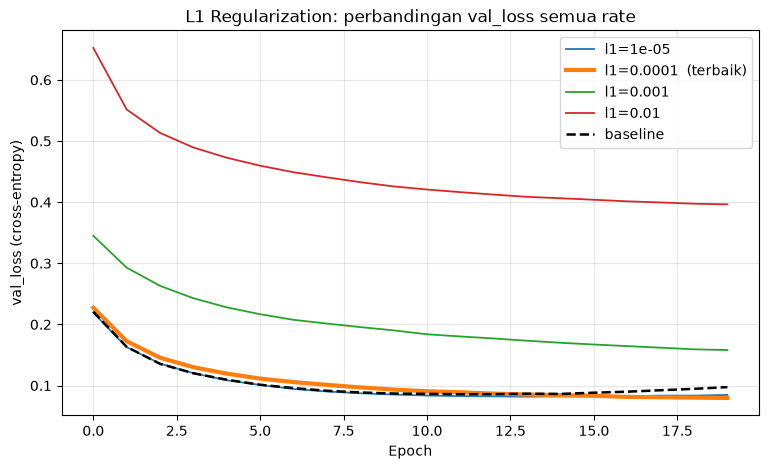

Model terbaik L1 Regularization -> l1=0.0001


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 152,672 (596.38 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 101,782 (397.59 KB)

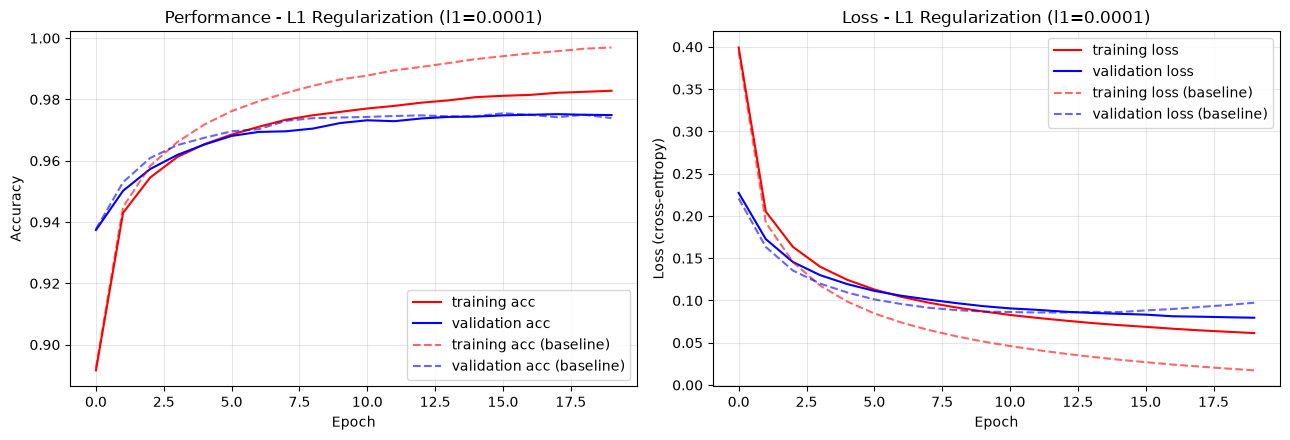

              precision    recall  f1-score   support

           0     0.9747    0.9827    0.9787       980
           1     0.9912    0.9877    0.9894      1135
           2     0.9784    0.9651    0.9717      1032
           3     0.9603    0.9822    0.9711      1010
           4     0.9707    0.9776    0.9741       982
           5     0.9807    0.9709    0.9758       892
           6     0.9811    0.9749    0.9780       958
           7     0.9841    0.9621    0.9729      1028
           8     0.9567    0.9743    0.9654       974
           9     0.9703    0.9703    0.9703      1009

    accuracy                         0.9749     10000
   macro avg     0.9748    0.9748    0.9747     10000
weighted avg     0.9750    0.9749    0.9749     10000



In [10]:
l1_rates = [1e-5, 1e-4, 1e-3, 1e-2]

l1_configs = [(f'l1={r:g}', {'l1': r}, None) for r in l1_rates]
l1_results, l1_best = run_search('L1 Regularization', l1_configs)
show_results('L1 Regularization', l1_results, l1_best)

#### 6.B L2 Regularization

L2 Regularization      | l2=1e-05               | epochs=20 | val_loss=0.0882 | val_acc=0.9738
L2 Regularization      | l2=0.0001              | epochs=20 | val_loss=0.0864 | val_acc=0.9730
L2 Regularization      | l2=0.001               | epochs=20 | val_loss=0.0832 | val_acc=0.9735
L2 Regularization      | l2=0.01                | epochs=20 | val_loss=0.1263 | val_acc=0.9632

>> Rate terbaik L2 Regularization: l2=0.001


,rate,epochs,val_loss,val_acc
0,l2=0.001,20,0.0832,0.9735
1,l2=0.0001,20,0.0864,0.9730
2,l2=1e-05,20,0.0882,0.9738
3,l2=0.01,20,0.1263,0.9632


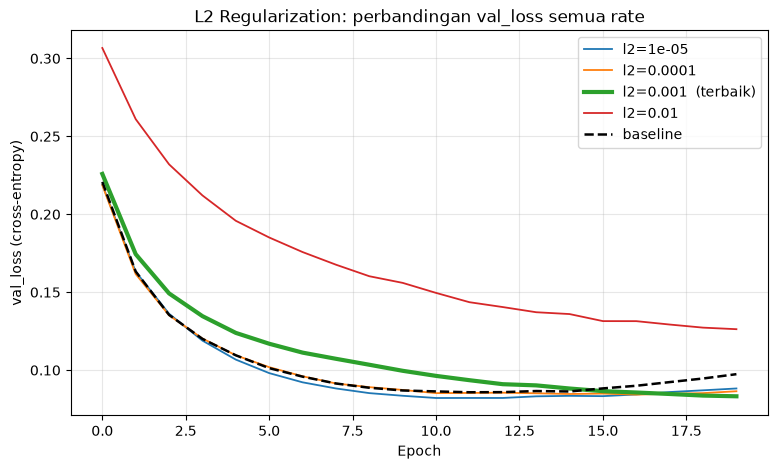

Model terbaik L2 Regularization -> l2=0.001


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_8 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 152,672 (596.38 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 101,782 (397.59 KB)

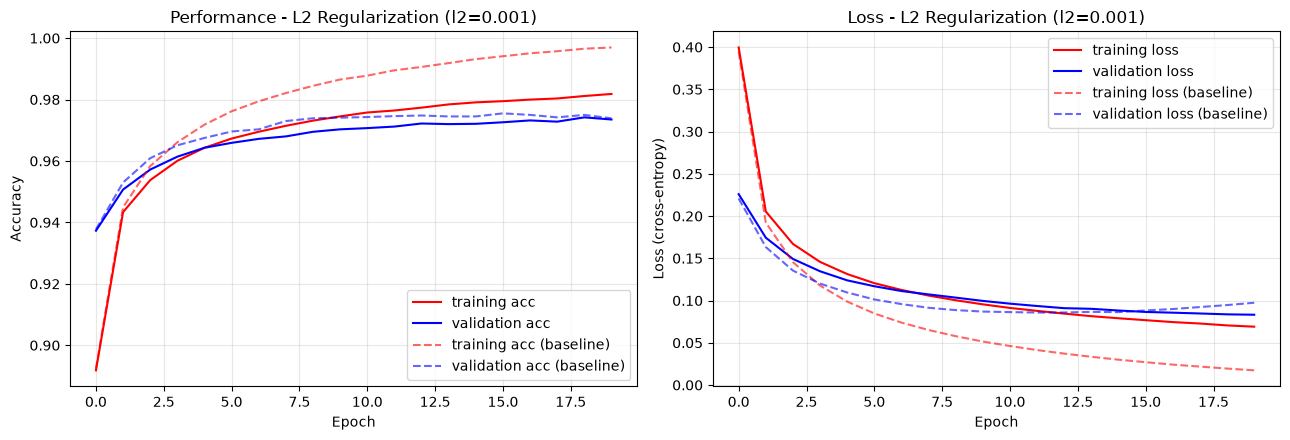

              precision    recall  f1-score   support

           0     0.9778    0.9867    0.9822       980
           1     0.9894    0.9877    0.9885      1135
           2     0.9725    0.9603    0.9664      1032
           3     0.9585    0.9822    0.9702      1010
           4     0.9706    0.9766    0.9736       982
           5     0.9850    0.9585    0.9716       892
           6     0.9761    0.9802    0.9781       958
           7     0.9821    0.9582    0.9700      1028
           8     0.9623    0.9702    0.9663       974
           9     0.9608    0.9722    0.9665      1009

    accuracy                         0.9735     10000
   macro avg     0.9735    0.9733    0.9733     10000
weighted avg     0.9736    0.9735    0.9735     10000



In [11]:
l2_rates = [1e-5, 1e-4, 1e-3, 1e-2]

l2_configs = [(f'l2={r:g}', {'l2': r}, None) for r in l2_rates]
l2_results, l2_best = run_search('L2 Regularization', l2_configs)
show_results('L2 Regularization', l2_results, l2_best)

#### 6.C Dropout

Dropout                | dropout=0.1            | epochs=20 | val_loss=0.0768 | val_acc=0.9768
Dropout                | dropout=0.2            | epochs=20 | val_loss=0.0782 | val_acc=0.9779
Dropout                | dropout=0.3            | epochs=20 | val_loss=0.0834 | val_acc=0.9768
Dropout                | dropout=0.4            | epochs=20 | val_loss=0.0899 | val_acc=0.9735
Dropout                | dropout=0.5            | epochs=20 | val_loss=0.1059 | val_acc=0.9687

>> Rate terbaik Dropout: dropout=0.1


,rate,epochs,val_loss,val_acc
0,dropout=0.1,20,0.0768,0.9768
1,dropout=0.2,20,0.0782,0.9779
2,dropout=0.3,20,0.0834,0.9768
3,dropout=0.4,20,0.0899,0.9735
4,dropout=0.5,20,0.1059,0.9687


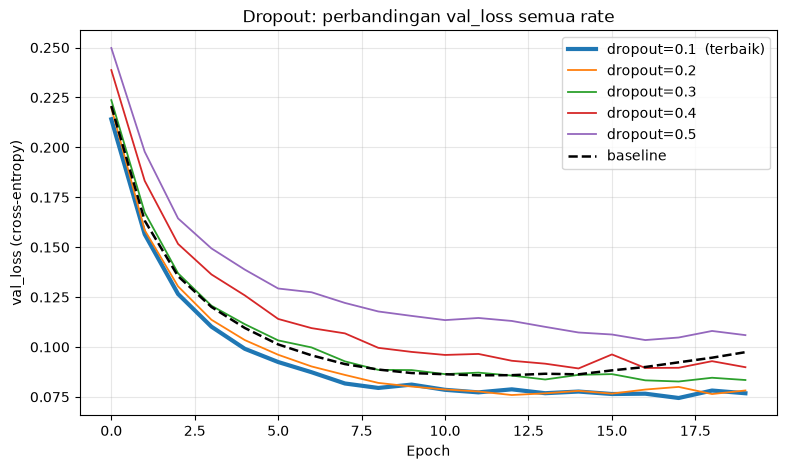

Model terbaik Dropout -> dropout=0.1


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_10 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 152,672 (596.38 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 101,782 (397.59 KB)

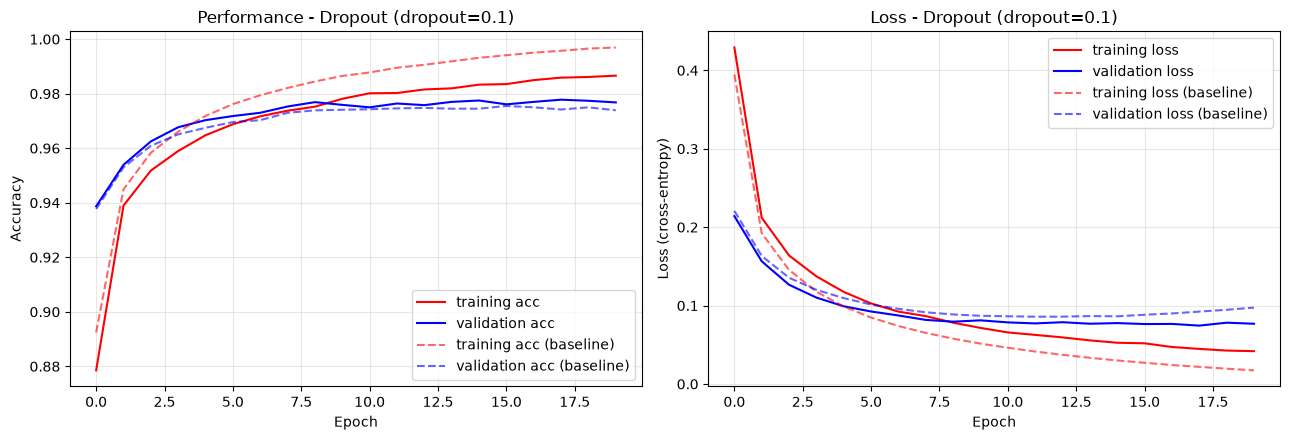

              precision    recall  f1-score   support

           0     0.9828    0.9898    0.9863       980
           1     0.9912    0.9877    0.9894      1135
           2     0.9694    0.9826    0.9759      1032
           3     0.9611    0.9792    0.9701      1010
           4     0.9804    0.9664    0.9733       982
           5     0.9786    0.9753    0.9770       892
           6     0.9822    0.9791    0.9807       958
           7     0.9793    0.9679    0.9736      1028
           8     0.9790    0.9589    0.9689       974
           9     0.9639    0.9792    0.9715      1009

    accuracy                         0.9768     10000
   macro avg     0.9768    0.9766    0.9767     10000
weighted avg     0.9769    0.9768    0.9768     10000



In [12]:
dropout_rates = [0.1, 0.2, 0.3, 0.4, 0.5]

do_configs = [(f'dropout={r}', {'dropout': r}, None) for r in dropout_rates]
do_results, do_best = run_search('Dropout', do_configs)
show_results('Dropout', do_results, do_best)

#### 6.D Early Stopping

Early Stopping         | patience=1             | epochs=13 | val_loss=0.0858 | val_acc=0.9746
Early Stopping         | patience=2             | epochs=14 | val_loss=0.0858 | val_acc=0.9746
Early Stopping         | patience=3             | epochs=15 | val_loss=0.0858 | val_acc=0.9746
Early Stopping         | patience=5             | epochs=17 | val_loss=0.0858 | val_acc=0.9746

>> Rate terbaik Early Stopping: patience=1


,rate,epochs,val_loss,val_acc
0,patience=1,13,0.0858,0.9746
1,patience=2,14,0.0858,0.9746
2,patience=3,15,0.0858,0.9746
3,patience=5,17,0.0858,0.9746


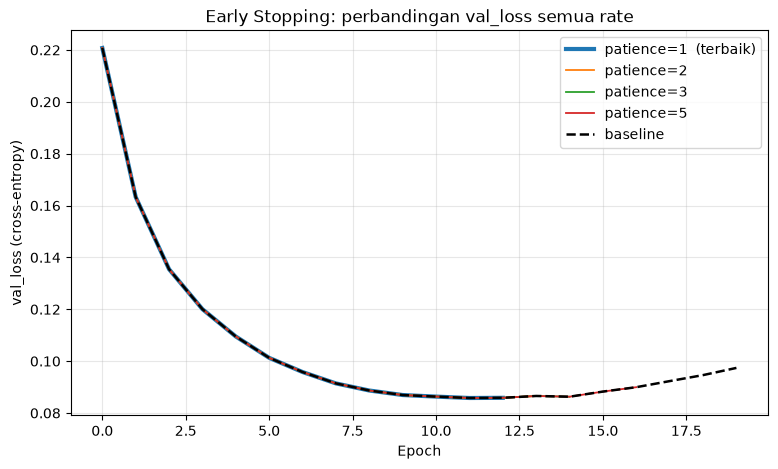

Model terbaik Early Stopping -> patience=1


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_15 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 152,672 (596.38 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 101,782 (397.59 KB)

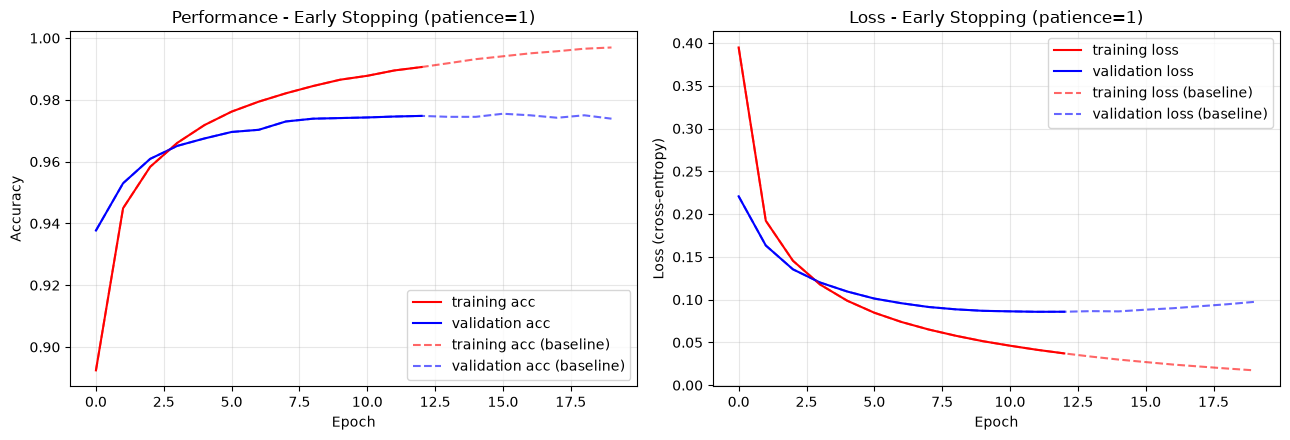

              precision    recall  f1-score   support

           0     0.9818    0.9918    0.9868       980
           1     0.9929    0.9824    0.9876      1135
           2     0.9646    0.9777    0.9711      1032
           3     0.9598    0.9703    0.9650      1010
           4     0.9747    0.9796    0.9771       982
           5     0.9762    0.9652    0.9707       892
           6     0.9781    0.9812    0.9797       958
           7     0.9811    0.9611    0.9710      1028
           8     0.9660    0.9620    0.9640       974
           9     0.9694    0.9732    0.9713      1009

    accuracy                         0.9746     10000
   macro avg     0.9745    0.9745    0.9744     10000
weighted avg     0.9747    0.9746    0.9746     10000



In [13]:
# Pada Early Stopping, "rate" yang dicari adalah nilai patience.
# Epoch maksimum dibuat lebih besar; training berhenti otomatis saat val_loss tidak membaik,
# lalu bobot dikembalikan ke epoch dengan val_loss terbaik.
patience_values = [1, 2, 3, 5]
ES_MAX_EPOCHS = 50

def make_es(p):
    return lambda: [EarlyStopping(monitor='val_loss', patience=p, restore_best_weights=True)]

es_configs = [(f'patience={p}', {}, make_es(p)) for p in patience_values]
es_results, es_best = run_search('Early Stopping', es_configs, epochs=ES_MAX_EPOCHS)
show_results('Early Stopping', es_results, es_best)

#### 6.E. L1 Regularization and Dropout 

L1 + Dropout           | l1=1e-05, dropout=0.2  | epochs=20 | val_loss=0.0727 | val_acc=0.9776
L1 + Dropout           | l1=1e-05, dropout=0.3  | epochs=20 | val_loss=0.0785 | val_acc=0.9769
L1 + Dropout           | l1=1e-05, dropout=0.5  | epochs=20 | val_loss=0.1032 | val_acc=0.9699
L1 + Dropout           | l1=0.0001, dropout=0.2 | epochs=20 | val_loss=0.0792 | val_acc=0.9758
L1 + Dropout           | l1=0.0001, dropout=0.3 | epochs=20 | val_loss=0.0841 | val_acc=0.9745
L1 + Dropout           | l1=0.0001, dropout=0.5 | epochs=20 | val_loss=0.1136 | val_acc=0.9646
L1 + Dropout           | l1=0.001, dropout=0.2  | epochs=20 | val_loss=0.1580 | val_acc=0.9549
L1 + Dropout           | l1=0.001, dropout=0.3  | epochs=20 | val_loss=0.1625 | val_acc=0.9546
L1 + Dropout           | l1=0.001, dropout=0.5  | epochs=20 | val_loss=0.1820 | val_acc=0.9470

>> Rate terbaik L1 + Dropout: l1=1e-05, dropout=0.2


,rate,epochs,val_loss,val_acc
0,"l1=1e-05, dropout=0.2",20,0.0727,0.9776
1,"l1=1e-05, dropout=0.3",20,0.0785,0.9769
2,"l1=0.0001, dropout=0.2",20,0.0792,0.9758
3,"l1=0.0001, dropout=0.3",20,0.0841,0.9745
4,"l1=1e-05, dropout=0.5",20,0.1032,0.9699
5,"l1=0.0001, dropout=0.5",20,0.1136,0.9646
6,"l1=0.001, dropout=0.2",20,0.1580,0.9549
7,"l1=0.001, dropout=0.3",20,0.1625,0.9546
8,"l1=0.001, dropout=0.5",20,0.1820,0.9470


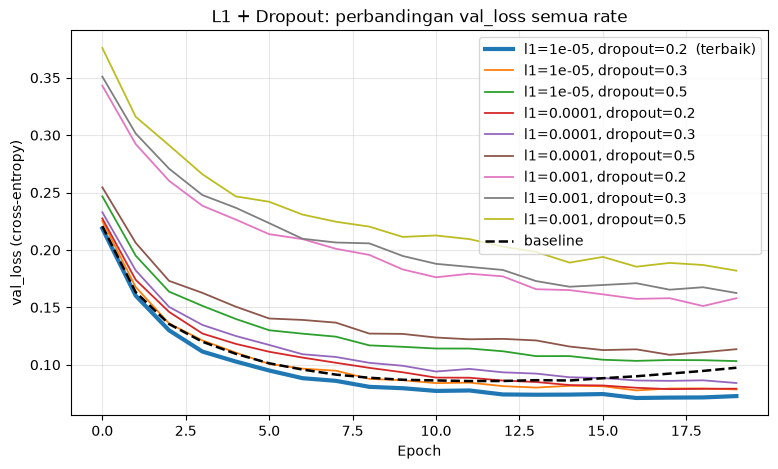

Model terbaik L1 + Dropout -> l1=1e-05, dropout=0.2


Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_19 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 152,672 (596.38 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 101,782 (397.59 KB)

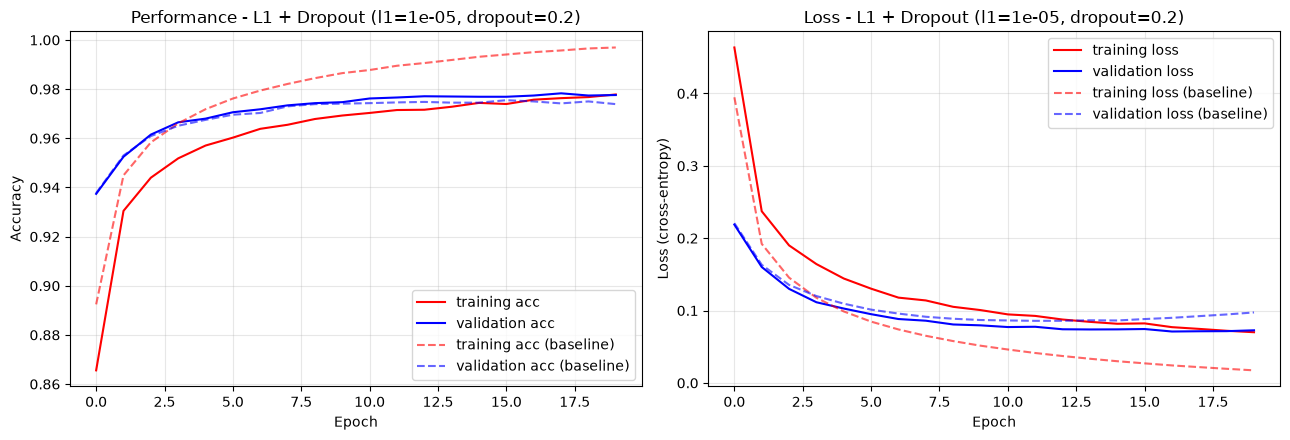

              precision    recall  f1-score   support

           0     0.9848    0.9918    0.9883       980
           1     0.9938    0.9850    0.9894      1135
           2     0.9647    0.9806    0.9726      1032
           3     0.9593    0.9792    0.9691      1010
           4     0.9826    0.9756    0.9790       982
           5     0.9819    0.9753    0.9786       892
           6     0.9863    0.9781    0.9822       958
           7     0.9831    0.9640    0.9735      1028
           8     0.9673    0.9723    0.9698       974
           9     0.9723    0.9732    0.9728      1009

    accuracy                         0.9776     10000
   macro avg     0.9776    0.9775    0.9775     10000
weighted avg     0.9777    0.9776    0.9776     10000



In [14]:
# Kombinasi L1 dan Dropout: grid kecil di sekitar rate yang umum dipakai
l1_combo = [1e-5, 1e-4, 1e-3]
do_combo = [0.2, 0.3, 0.5]

combo_configs = [(f'l1={a:g}, dropout={b}', {'l1': a, 'dropout': b}, None)
                 for a in l1_combo for b in do_combo]
combo_results, combo_best = run_search('L1 + Dropout', combo_configs)
show_results('L1 + Dropout', combo_results, combo_best)

### 7. Kesimpulan

hasil rate terbaik masing-masing metode dibadningkan untuk menemukan metode paling bagus

,metode,rate_terbaik,epochs,val_loss,val_acc,train_val_gap
0,L1 + Dropout,"l1=1e-05, dropout=0.2",20,0.0727,0.9776,0.0027
1,Dropout,dropout=0.1,20,0.0768,0.9768,0.0350
2,L1 Regularization,l1=0.0001,20,0.0796,0.9749,0.0182
3,L2 Regularization,l2=0.001,20,0.0832,0.9735,0.0141
4,Early Stopping,patience=1,13,0.0858,0.9746,0.0487
5,Baseline,tanpa regularisasi,20,0.0974,0.9739,0.0800


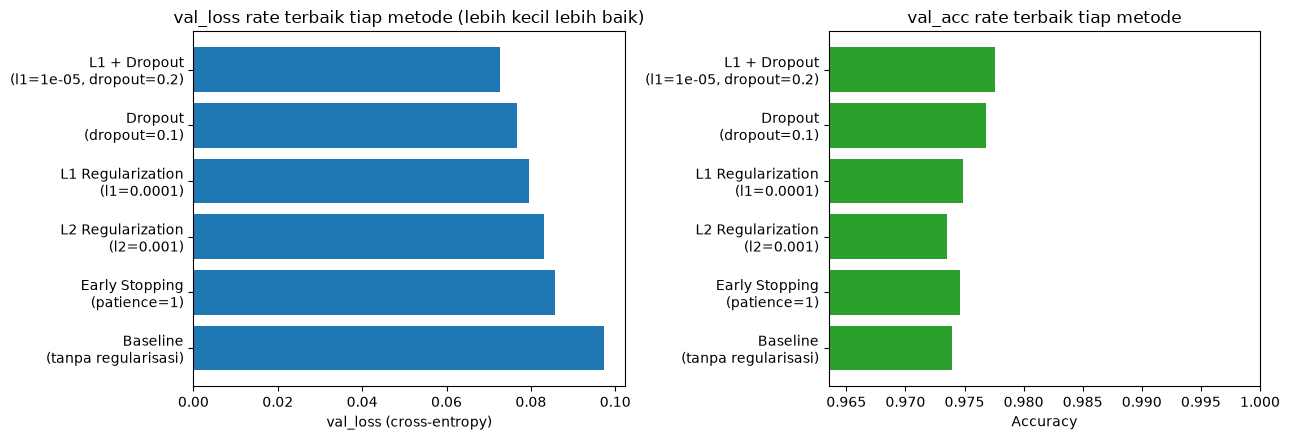

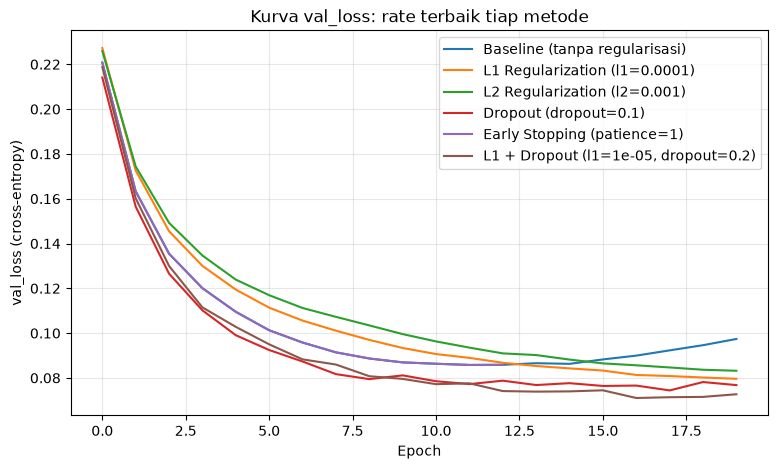

Metode terbaik: L1 + Dropout dengan l1=1e-05, dropout=0.2
val_loss = 0.0727, val_acc = 0.9776


In [ ]:
summary = (pd.DataFrame(best_per_method)
             .sort_values('val_loss')
             .reset_index(drop=True))
summary['val_loss'] = summary['val_loss'].round(4)
summary['val_acc'] = summary['val_acc'].round(4)
summary['train_val_gap'] = summary['train_val_gap'].round(4)
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
labels = summary['metode'] + '\n(' + summary['rate_terbaik'] + ')'
ax[0].barh(labels, summary['val_loss'], color='tab:blue')
ax[0].invert_yaxis(); ax[0].set_title('val_loss rate terbaik tiap metode (lebih kecil lebih baik)')
ax[0].set_xlabel('val_loss (cross-entropy)')
ax[1].barh(labels, summary['val_acc'], color='tab:green')
ax[1].invert_yaxis(); ax[1].set_title('val_acc rate terbaik tiap metode')
ax[1].set_xlim(summary['val_acc'].min() - 0.01, 1.0); ax[1].set_xlabel('Accuracy')
plt.tight_layout(); plt.show()

# Perbandingan kurva val_loss rate terbaik semua metode
all_results = {'Baseline': (baseline_results, baseline_best),
               'L1 Regularization': (l1_results, l1_best),
               'L2 Regularization': (l2_results, l2_best),
               'Dropout': (do_results, do_best),
               'Early Stopping': (es_results, es_best),
               'L1 + Dropout': (combo_results, combo_best)}
plt.figure(figsize=(9, 5))
for name, (res, b) in all_results.items():
    plt.plot(res[b]['history']['val_ce'], label=f'{name} ({b})')
plt.title('Kurva val_loss: rate terbaik tiap metode')
plt.xlabel('Epoch'); plt.ylabel('val_loss (cross-entropy)')
plt.legend(); plt.grid(alpha=.3); plt.show()

top = summary.iloc[0]
print(f"Metode terbaik: {top['metode']} dengan {top['rate_terbaik']}")
print(f"val_loss = {top['val_loss']:.4f}, val_acc = {top['val_acc']:.4f}")

**Cara membaca hasil:**
- `val_loss` paling kecil = model paling baik dalam memprediksi data yang tidak dilihat saat training; ini kriteria utama pemilihan.
- `train_val_gap` (val_loss − training loss di epoch terakhir) menunjukkan seberapa besar overfitting. Nilai mendekati 0 berarti model tidak menghafal data training.
- Baseline menjadi pembanding: metode yang val_loss-nya tidak lebih kecil dari baseline berarti tidak membantu pada rate tersebut.